<a href="https://colab.research.google.com/github/EduardoKenzoHayashi/CN-Lobosco/blob/main/Aula_Metodo_SOR_Calculo_Numerico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Método SOR: resolvendo sistemas lineares passo a passo

**Aula didática de Cálculo Numérico — duração sugerida: 3 horas**

Neste notebook vamos entender e implementar o método de **sobre-relaxação sucessiva** (*Successive Over-Relaxation*, SOR). Ao final, você deverá conseguir:

- explicar a ideia iterativa e o papel do parâmetro de relaxação $\omega$;
- implementar SOR e testar o critério de parada;
- comparar diferentes valores de $\omega$ e discutir a convergência.

**Pré-requisitos:** sistemas lineares, matrizes e vetores, noções básicas de Python.

> O método SOR é uma extensão do Gauss-Seidel. Para $\omega=1$, SOR coincide com Gauss-Seidel.


## 1. Motivação: resolver $A\mathbf{x}=\mathbf{b}$

Em problemas grandes e esparsos, métodos diretos como eliminação de Gauss podem exigir muita memória e cálculo. Métodos iterativos começam com uma aproximação $\mathbf{x}^{(0)}$ e a atualizam até que a solução aproximada seja suficientemente precisa.

A questão é: **como usar as equações do sistema para melhorar repetidamente uma estimativa?**


In [15]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)


### Exemplo: sistema linear para aplicar o método SOR

Considere o seguinte sistema linear:

$$
\begin{cases}
4x_1 - x_2 = 3,\\
-x_1 + 4x_2 - x_3 = 4,\\
-x_2 + 3x_3 = 2.
\end{cases}
$$

Em forma matricial, escrevemos $A\mathbf{x}=\mathbf{b}$, em que

$$
A =
\begin{bmatrix}
4 & -1 & 0 \\
-1 & 4 & -1 \\
0 & -1 & 3
\end{bmatrix},
\qquad
\mathbf{x} =
\begin{bmatrix}
x_1 \\
x_2 \\
x_3
\end{bmatrix},
\qquad
\mathbf{b} =
\begin{bmatrix}
3 \\
4 \\
2
\end{bmatrix}.
$$

Esse sistema é pequeno o suficiente para acompanharmos as iterações à mão. Além disso, sua solução exata é

$$
\mathbf{x} =
\begin{bmatrix}
1 \\
1 \\
1
\end{bmatrix}.
$$

Assim, podemos comparar as aproximações calculadas pelo método SOR com a solução exata.

Na prática, o método SOR não precisa conhecer a solução exata. Para iniciar as iterações, precisamos apenas da matriz $A$, do vetor $\mathbf{b}$, de uma estimativa inicial para a solução e do parâmetro de relaxação $\omega$.

In [16]:
A = np.array([[4., -1., 0.],
              [-1., 4., -1.],
              [0., -1., 3.]])
b = np.array([3., 4., 2.])
x_exata = np.linalg.solve(A, b)
print("Solução de referência:", x_exata)
print("Resíduo da solução de referência:", np.linalg.norm(b - A @ x_exata))


Solução de referência: [1.146341 1.585366 1.195122]
Resíduo da solução de referência: 4.965068306494546e-16


## 2. Da substituição a Gauss-Seidel

Para resolver o sistema, podemos isolar uma incógnita em cada equação. Em geral, a $i$-ésima equação de um sistema linear pode ser escrita como

$$
a_{ii}x_i+\sum_{j\ne i}a_{ij}x_j=b_i.
$$

Isolando $x_i$, obtemos

$$
x_i=\frac{1}{a_{ii}}\left(b_i-\sum_{j\ne i}a_{ij}x_j\right).
$$

Essa expressão sugere um processo iterativo: começamos com uma estimativa inicial para as incógnitas e usamos as equações para calcular valores atualizados. No método de **Gauss-Seidel**, as incógnitas são atualizadas uma de cada vez, seguindo a ordem das equações. Assim que calculamos um novo valor, usamos esse valor atualizado nos cálculos seguintes da mesma iteração. Para as incógnitas que ainda não foram atualizadas, usamos os valores da iteração anterior.

Aplicando esse procedimento ao sistema do exemplo,

$$
\begin{aligned}
4x_1-x_2 &= 3,\\
-x_1+4x_2-x_3 &= 4,\\
-x_2+3x_3 &= 2,
\end{aligned}
$$

isolamos cada incógnita:

$$
\begin{aligned}
x_1 &= \frac{3+x_2}{4},\\
x_2 &= \frac{4+x_1+x_3}{4},\\
x_3 &= \frac{2+x_2}{3}.
\end{aligned}
$$

Vamos iniciar com a estimativa

$$
\mathbf{x}^{(0)}=
\begin{bmatrix}
0\\
0\\
0
\end{bmatrix}.
$$

Em uma iteração de Gauss-Seidel, calculamos os componentes em sequência:

1. **Atualizamos $x_1$** usando o valor antigo de $x_2$:

   $$
   x_1^{(1)}=\frac{3+x_2^{(0)}}{4}
   =\frac{3+0}{4}=0{,}75.
   $$

2. **Atualizamos $x_2$** usando o valor recém-calculado de $x_1$ e o valor antigo de $x_3$:

   $$
   x_2^{(1)}=\frac{4+x_1^{(1)}+x_3^{(0)}}{4}
   =\frac{4+0{,}75+0}{4}=1{,}1875.
   $$

3. **Atualizamos $x_3$** usando o valor recém-calculado de $x_2$:

   $$
   x_3^{(1)}=\frac{2+x_2^{(1)}}{3}
   =\frac{2+1{,}1875}{3}\approx 1{,}0625.
   $$

Portanto, após a primeira iteração, temos

$$
\mathbf{x}^{(1)}\approx
\begin{bmatrix}
0{,}75\\
1{,}1875\\
1{,}0625
\end{bmatrix}.
$$

Observe que essa aproximação ainda não é a solução exata $(1,1,1)^T$. O processo pode ser repetido, usando $\mathbf{x}^{(1)}$ como ponto de partida, para obter aproximações sucessivamente melhores.



In [17]:
x0 = np.zeros(3)
x1_gs = np.zeros(3)
x1_gs[0] = (b[0] - A[0,1]*x0[1] - A[0,2]*x0[2]) / A[0,0]
x1_gs[1] = (b[1] - A[1,0]*x1_gs[0] - A[1,2]*x0[2]) / A[1,1]
x1_gs[2] = (b[2] - A[2,0]*x1_gs[0] - A[2,1]*x1_gs[1]) / A[2,2]
print("Primeira iteração Gauss-Seidel:", x1_gs)


Primeira iteração Gauss-Seidel: [0.75   1.1875 1.0625]


## 3. A ideia do SOR: corrigir e relaxar

O método SOR (*Successive Over-Relaxation*, ou **sobre-relaxação sucessiva**) parte da mesma ideia de atualização em sequência usada pelo método de Gauss-Seidel. A diferença é que, em vez de aceitar diretamente o valor calculado por Gauss-Seidel, o SOR ajusta o tamanho do passo usando um parâmetro chamado **parâmetro de relaxação**, representado por $\omega$.

### 3.1 O valor proposto por Gauss-Seidel

Na atualização da incógnita $x_i$, o método de Gauss-Seidel calcula um valor proposto, que podemos representar por $\widehat{x}_i^{(k+1)}$. Esse valor é obtido isolando $x_i$ na equação correspondente e usando:

- os valores já atualizados na iteração atual para as incógnitas anteriores;
- os valores da iteração anterior para as incógnitas ainda não atualizadas.

Para o sistema do exemplo, a primeira atualização de Gauss-Seidel, a partir de $\mathbf{x}^{(0)}=(0,0,0)^T$, fornece:

$$
\widehat{x}_1^{(1)}=\frac{3+x_2^{(0)}}{4}
=\frac{3+0}{4}=0{,}75.
$$

Esse é o valor que Gauss-Seidel usaria diretamente para substituir a estimativa antiga de $x_1$.

### 3.2 Como o SOR modifica a atualização

O SOR combina o valor antigo $x_i^{(k)}$ com o valor proposto por Gauss-Seidel:

$$
x_i^{(k+1)}
=
(1-\omega)x_i^{(k)}
+
\omega\widehat{x}_i^{(k+1)}.
$$

Uma forma equivalente, que evidencia a **correção**, é:

$$
x_i^{(k+1)}
=
x_i^{(k)}
+
\omega\left(\widehat{x}_i^{(k+1)}-x_i^{(k)}\right).
$$

A diferença $\widehat{x}_i^{(k+1)}-x_i^{(k)}$ é a mudança que Gauss-Seidel faria. O parâmetro $\omega$ multiplica essa mudança:

- quando $\omega<1$, usamos apenas uma parte da mudança proposta;
- quando $\omega=1$, usamos a mudança completa;
- quando $\omega>1$, avançamos mais do que a mudança proposta.

Assim, $\omega$ controla o tamanho do passo em cada atualização.

### 3.3 Interpretando os valores de $\omega$

- **$0<\omega<1$ — sub-relaxação:** avançamos apenas parcialmente na direção do valor proposto. Isso pode tornar as atualizações mais cautelosas, embora também possa aumentar o número de iterações.
- **$\omega=1$ — Gauss-Seidel:** o valor proposto é usado diretamente. Nesse caso, o SOR coincide com o método de Gauss-Seidel.
- **$1<\omega<2$ — sobre-relaxação:** avançamos além do valor proposto. Para certos sistemas, isso pode acelerar a convergência.

### 3.4 Exemplo da primeira atualização

Na primeira equação do nosso sistema, temos $x_1^{(0)}=0$ e o valor proposto por Gauss-Seidel é $\widehat{x}_1^{(1)}=0{,}75$.

Se escolhermos $\omega=1{,}2$, a atualização SOR será:

$$
\begin{aligned}
x_1^{(1)}
&=(1-1{,}2)x_1^{(0)}+1{,}2\widehat{x}_1^{(1)}\\
&=(1-1{,}2)(0)+1{,}2(0{,}75)\\
&=0{,}9.
\end{aligned}
$$

Com Gauss-Seidel, obteríamos $x_1^{(1)}=0{,}75$. Com $\omega=1{,}2$, o SOR aplica uma correção maior e obtém $x_1^{(1)}=0{,}9$. Esse passo maior pode aproximar a solução mais rapidamente, mas não garante que isso aconteça.

### 3.5 Fórmula completa do SOR

Substituindo a expressão de Gauss-Seidel na fórmula de atualização, obtemos:

$$
x_i^{(k+1)}
=
(1-\omega)x_i^{(k)}
+
\frac{\omega}{a_{ii}}
\left(
b_i
-
\sum_{j<i}a_{ij}x_j^{(k+1)}
-
\sum_{j>i}a_{ij}x_j^{(k)}
\right).
$$

Note a diferença entre as duas somas:

- para $j<i$, usamos $x_j^{(k+1)}$, pois essas componentes já foram atualizadas na iteração atual;
- para $j>i$, usamos $x_j^{(k)}$, pois essas componentes ainda não foram atualizadas.

### Atenção à convergência

Escolher $\omega>1$ não significa automaticamente que o método será mais rápido. Um valor adequado depende do sistema linear: um parâmetro pode acelerar a convergência em um problema e torná-la mais lenta em outro. Uma escolha inadequada pode até impedir a convergência.

Por isso, nos próximos passos, vamos implementar o método, testar diferentes valores de $\omega$ e acompanhar o resíduo para avaliar o comportamento das iterações.

### Exemplo passo a passo: uma iteração do método SOR

Vamos aplicar o método SOR ao sistema do exemplo, usando o parâmetro de relaxação $\omega=1{,}2$ e a estimativa inicial

$$
\mathbf{x}^{(0)}=
\begin{bmatrix}
0\\
0\\
0
\end{bmatrix}.
$$

Em cada equação, primeiro calculamos o valor que seria proposto pelo método de Gauss-Seidel. Depois, usamos $\omega$ para ajustar o tamanho da correção. Como as incógnitas são atualizadas em sequência, os valores calculados na iteração atual são usados imediatamente nas equações seguintes.

A fórmula de atualização é

$$
x_i^{(k+1)}
=
(1-\omega)x_i^{(k)}
+
\omega\widehat{x}_i^{(k+1)},
$$

em que $\widehat{x}_i^{(k+1)}$ é o valor proposto por Gauss-Seidel.

**1. Atualização de $x_1$**

A primeira equação é $4x_1-x_2=3$. Usando o valor inicial $x_2^{(0)}=0$, o valor proposto por Gauss-Seidel é

$$
\widehat{x}_1^{(1)}
=
\frac{3+x_2^{(0)}}{4}
=
\frac{3}{4}
=
0{,}75.
$$

Agora aplicamos a correção SOR:

$$
\begin{aligned}
x_1^{(1)}
&=(1-1{,}2)x_1^{(0)}+1{,}2\widehat{x}_1^{(1)}\\
&=(1-1{,}2)(0)+1{,}2(0{,}75)\\
&=0{,}9.
\end{aligned}
$$

**2. Atualização de $x_2$**

A segunda equação é $-x_1+4x_2-x_3=4$. Para calcular o valor proposto, usamos o valor recém-atualizado $x_1^{(1)}=0{,}9$ e o valor antigo $x_3^{(0)}=0$:

$$
\widehat{x}_2^{(1)}
=
\frac{4+x_1^{(1)}+x_3^{(0)}}{4}
=
\frac{4+0{,}9+0}{4}
=
1{,}225.
$$

Aplicando a fórmula SOR:

$$
\begin{aligned}
x_2^{(1)}
&=(1-1{,}2)x_2^{(0)}+1{,}2\widehat{x}_2^{(1)}\\
&=(1-1{,}2)(0)+1{,}2(1{,}225)\\
&=1{,}47.
\end{aligned}
$$

**3. Atualização de $x_3$**

A terceira equação é $-x_2+3x_3=2$. Como $x_2$ já foi atualizado nesta iteração, usamos $x_2^{(1)}=1{,}47$:

$$
\widehat{x}_3^{(1)}
=
\frac{2+x_2^{(1)}}{3}
=
\frac{2+1{,}47}{3}
\approx
1{,}156667.
$$

Aplicando novamente a correção SOR:

$$
\begin{aligned}
x_3^{(1)}
&=(1-1{,}2)x_3^{(0)}+1{,}2\widehat{x}_3^{(1)}\\
&=(1-1{,}2)(0)+1{,}2(1{,}156667)\\
&=1{,}388.
\end{aligned}
$$

Assim, ao final da primeira iteração, obtemos

$$
\mathbf{x}^{(1)}
\approx
\begin{bmatrix}
0{,}9\\
1{,}47\\
1{,}388
\end{bmatrix}.
$$

Aproximações diferentes podem resultar da escolha de $\omega$. Aqui, usamos $\omega=1{,}2$, que produz correções maiores do que Gauss-Seidel. Isso não garante que o método vá convergir mais rapidamente; vamos avaliar seu comportamento acompanhando as iterações e o resíduo.



In [18]:
omega = 1.2
x1_sor = np.zeros(3)
for i in range(3):
    soma = b[i] - np.dot(A[i, :i], x1_sor[:i]) - np.dot(A[i, i+1:], x0[i+1:])
    gs_proposto = soma / A[i, i]
    x1_sor[i] = (1 - omega) * x0[i] + omega * gs_proposto
print("Primeira iteração SOR:", x1_sor)


Primeira iteração SOR: [0.9   1.47  1.388]


## 4. Antes do código: quando esperamos convergência?

Antes de executar o método SOR, é útil perguntar: **as aproximações vão se aproximar da solução ou se afastar dela?**

Um método iterativo converge quando, a cada iteração, as aproximações ficam progressivamente mais próximas da solução. No SOR, isso depende da matriz $A$, da ordem das equações e do parâmetro de relaxação $\omega$. Portanto, escolher um valor de $\omega$ entre 0 e 2, por si só, **não garante** a convergência para qualquer sistema.

### Uma condição suficiente para o SOR

Um resultado conhecido garante a convergência do SOR quando:

1. a matriz $A$ é **simétrica definida positiva**; e
2. o parâmetro de relaxação satisfaz $0<\omega<2$.

Uma matriz é simétrica quando $A=A^T$. Ela é definida positiva quando $\mathbf{y}^T A\mathbf{y}>0$ para todo vetor $\mathbf{y}\ne\mathbf{0}$.

Essa condição é **suficiente**: quando ela é satisfeita, podemos concluir que o método converge. Porém, ela não é necessária em todos os casos. Isso significa que o SOR também pode convergir para algumas matrizes que não atendem a essa condição.

### Verificando a simetria no exemplo

A matriz do nosso sistema é

$$
A=
\begin{bmatrix}
4 & -1 & 0\\
-1 & 4 & -1\\
0 & -1 & 3
\end{bmatrix}.
$$

Ela é simétrica porque seus elementos espelhados em relação à diagonal principal são iguais: $a_{12}=a_{21}=-1$, $a_{13}=a_{31}=0$ e $a_{23}=a_{32}=-1$.

Também podemos verificar que ela é definida positiva observando seus menores principais:

$$
\det([4])=4>0,
$$

$$
\det
\begin{bmatrix}
4 & -1\\
-1 & 4
\end{bmatrix}
=16-1=15>0,
$$

$$
\det(A)=39>0.
$$

Como todos são positivos, o critério de Sylvester confirma que $A$ é definida positiva. Portanto, para este exemplo, o SOR converge quando $0<\omega<2$.

### Diagonal dominante: outra propriedade útil

Uma matriz é estritamente diagonal dominante por linhas quando, em cada linha $i$,

$$
|a_{ii}|>\sum_{j\ne i}|a_{ij}|.
$$

Isto é, o valor absoluto do elemento da diagonal principal precisa ser maior que a soma dos valores absolutos dos demais elementos da mesma linha.

Para verificar essa propriedade no nosso exemplo, comparamos as quantidades linha a linha:

| Linha | $|a_{ii}|$ | $\sum_{j\ne i}|a_{ij}|$ | Comparação |
|---|---:|---:|---|
| 1 | $|4|=4$ | $|-1|+|0|=1$ | $4>1$ |
| 2 | $|4|=4$ | $|-1|+|-1|=2$ | $4>2$ |
| 3 | $|3|=3$ | $|0|+|-1|=1$ | $3>1$ |

Assim, a matriz do exemplo também é estritamente diagonal dominante.

A diagonal dominante é uma condição suficiente importante para a convergência de métodos como Jacobi e Gauss-Seidel. Para o SOR, a garantia apresentada acima — matriz simétrica definida positiva e $0<\omega<2$ — é a que usaremos neste exemplo.

### O que essas verificações nos dizem — e o que não dizem

As condições de convergência ajudam a decidir se há uma garantia teórica para o método, mas não indicam necessariamente qual valor de $\omega$ será mais rápido. Mesmo quando sabemos que o método converge, diferentes valores de $\omega$ podem exigir quantidades muito diferentes de iterações.

Por isso, além de verificar as condições da matriz, vamos acompanhar numericamente:

- a mudança entre duas aproximações consecutivas;
- o resíduo, calculado por $\mathbf{r}^{(k)}=\mathbf{b}-A\mathbf{x}^{(k)}$.

Um resíduo pequeno indica que a aproximação satisfaz bem o sistema. No código, também limitaremos o número máximo de iterações para identificar casos em que o critério de parada não é atingido.

**Pergunta para discussão:** a matriz deste exemplo satisfaz tanto a condição de simetria definida positiva quanto a de diagonal dominante estrita? O que podemos concluir sobre a convergência do SOR para $0<\omega<2$?

In [19]:
def diagonally_dominant(A):
    d = np.abs(np.diag(A))
    off = np.sum(np.abs(A), axis=1) - d
    return np.all(d >= off), d, off

flag, diagonal, fora_diagonal = diagonally_dominant(A)
print("Diagonal dominante (fraca):", flag)
print("Diagonal |a_ii|:", diagonal)
print("Soma fora da diagonal:", fora_diagonal)


Diagonal dominante (fraca): True
Diagonal |a_ii|: [4. 4. 3.]
Soma fora da diagonal: [1. 2. 1.]


## 5. Implementando o SOR com cuidado

Ao implementar um método iterativo, precisamos definir não apenas como calcular a próxima aproximação, mas também **como decidir se já podemos parar**.

Para isso, acompanharemos dois indicadores a cada iteração:

1. **Diferença entre iteradas**

   $$
   \left\|\mathbf{x}^{(k+1)}-\mathbf{x}^{(k)}\right\|_\infty.
   $$

   Esse valor mede a maior mudança entre as componentes de duas aproximações consecutivas. A norma infinito de um vetor é o maior valor absoluto de suas componentes. Portanto,

   $$
   \left\|\mathbf{x}^{(k+1)}-\mathbf{x}^{(k)}\right\|_\infty
   =
   \max_i\left|x_i^{(k+1)}-x_i^{(k)}\right|.
   $$

   Se essa diferença é pequena, significa que a aproximação quase não mudou de uma iteração para a seguinte.

2. **Resíduo do sistema**

   $$
   \left\|\mathbf{b}-A\mathbf{x}^{(k+1)}\right\|_\infty.
   $$

   O vetor $\mathbf{r}^{(k+1)}=\mathbf{b}-A\mathbf{x}^{(k+1)}$ é chamado de **resíduo**. Ele indica o quanto a aproximação atual deixa de satisfazer o sistema original. Se o resíduo é pequeno, então $A\mathbf{x}^{(k+1)}$ está próximo de $\mathbf{b}$.

Esses indicadores medem coisas diferentes. A diferença entre iteradas informa quanto a aproximação mudou; o resíduo informa quão bem ela satisfaz o sistema. Uma mudança pequena, sozinha, não garante que encontramos uma boa solução: o processo pode estar avançando muito lentamente ou ter estabilizado longe da solução.

Por isso, neste notebook, consideraremos que o método convergiu quando **os dois indicadores forem menores que a tolerância escolhida**. Também definiremos um número máximo de iterações. Assim, o algoritmo termina mesmo quando não consegue atingir a tolerância, e podemos verificar esse resultado explicitamente.

No código, usaremos a norma infinito e uma tolerância `tol`. Por exemplo, `tol=1e-10` exige que tanto a maior mudança entre iteradas quanto o resíduo sejam menores que $10^{-10}$. Uma tolerância menor pede um resultado mais rigoroso, mas pode exigir mais iterações.

> **Observação:** em cálculos numéricos, a precisão da máquina é finita. Por isso, não é necessário esperar que a diferença e o resíduo sejam exatamente zero; verificamos se são suficientemente pequenos para a precisão desejada.

In [20]:
def sor(A, b, omega=1.0, x0=None, tol=1e-10, max_iter=10000):
    """Resolve Ax=b por SOR. Retorna x e histórico dos erros e resíduos."""
    A = np.asarray(A, dtype=float)
    b = np.asarray(b, dtype=float)
    n = len(b)
    if A.shape != (n, n):
        raise ValueError("A deve ser quadrada e compatível com b")
    if np.any(np.isclose(np.diag(A), 0)):
        raise ValueError("A diagonal não pode conter zeros")
    if not (0 < omega < 2):
        raise ValueError("Para esta aula, use 0 < omega < 2")
    x = np.zeros(n) if x0 is None else np.array(x0, dtype=float).copy()
    if x.shape != (n,):
        raise ValueError("x0 deve ter o mesmo tamanho de b")
    hist = {"delta": [], "residuo": []}
    for k in range(max_iter):
        x_ant = x.copy()
        for i in range(n):
            soma_novos = np.dot(A[i, :i], x[:i])
            soma_antigos = np.dot(A[i, i+1:], x_ant[i+1:])
            gs_proposto = (b[i] - soma_novos - soma_antigos) / A[i, i]
            x[i] = (1 - omega) * x_ant[i] + omega * gs_proposto
        delta = np.linalg.norm(x - x_ant, ord=np.inf)
        residuo = np.linalg.norm(b - A @ x, ord=np.inf)
        hist["delta"].append(delta)
        hist["residuo"].append(residuo)
        if delta < tol and residuo < tol:
            return x, hist, k + 1, True
    return x, hist, max_iter, False


In [21]:
x, hist, n_iter, convergiu = sor(A, b, omega=1.2, x0=np.zeros(3))
print("Convergiu?", convergiu)
print("Iterações:", n_iter)
print("Aproximação:", x)
print("Erro relativo à solução de referência:", np.linalg.norm(x - x_exata) / np.linalg.norm(x_exata))
print("Resíduo infinito:", np.linalg.norm(b - A @ x, ord=np.inf))


Convergiu? True
Iterações: 17
Aproximação: [1.146341 1.585366 1.195122]
Erro relativo à solução de referência: 2.1398916512490397e-12
Resíduo infinito: 1.247979497520646e-11


### Conferência do algoritmo

Se o resultado não for próximo de $(1,1,1)^T$, reveja:

- se componentes já atualizadas entram na soma da iteração atual;
- se $x_i^{(k)}$ (valor antigo) é usado no termo $(1-\omega)x_i^{(k)}$;
- se o resíduo foi calculado como $b-Ax$;
- se o critério de parada verifica ambos os indicadores.


## 6. Experimento: como $\omega$ afeta o desempenho?

Execute o método para vários valores.

In [22]:
omegas = [0.5, 0.8, 1.0, 1.2, 1.5, 1.8]
resultados = []
historicos = {}
for w in omegas:
    sol, h, n, ok = sor(A, b, omega=w, tol=1e-10)
    resultados.append((w, n, ok, np.linalg.norm(b-A@sol, ord=np.inf)))
    historicos[w] = h
for linha in resultados:
    print(f"omega={linha[0]:.1f} | iterações={linha[1]:4d} | convergiu={linha[2]} | resíduo={linha[3]:.2e}")


omega=0.5 | iterações=  58 | convergiu=True | resíduo=8.28e-11
omega=0.8 | iterações=  27 | convergiu=True | resíduo=5.43e-11
omega=1.0 | iterações=  14 | convergiu=True | resíduo=3.14e-11
omega=1.2 | iterações=  17 | convergiu=True | resíduo=1.25e-11
omega=1.5 | iterações=  37 | convergiu=True | resíduo=4.45e-11
omega=1.8 | iterações= 111 | convergiu=True | resíduo=8.24e-11


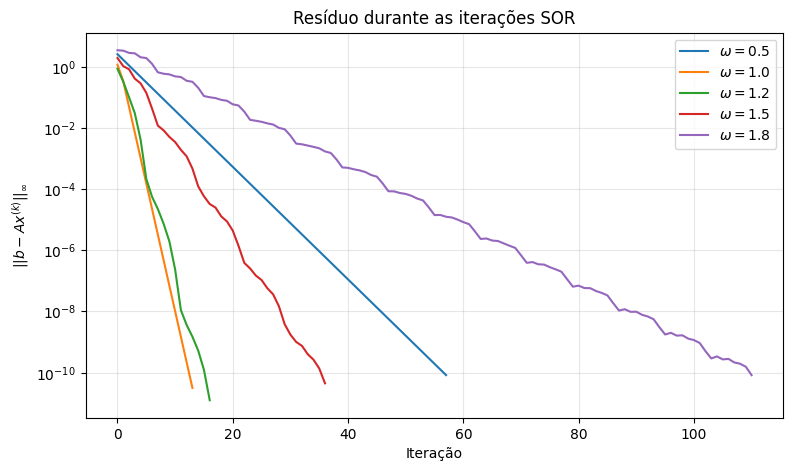

In [23]:
plt.figure(figsize=(9, 5))
for w in [0.5, 1.0, 1.2, 1.5, 1.8]:
    plt.semilogy(historicos[w]["residuo"], label=fr"$\omega={w}$")
plt.xlabel("Iteração")
plt.ylabel(r"$||b-Ax^{(k)}||_\infty$")
plt.title("Resíduo durante as iterações SOR")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()


### Interpretando o gráfico

Discuta em dupla: qual curva cai mais rapidamente? A curva mais rápida para este sistema será sempre a melhor para outra matriz? O que acontece com a forma das curvas quando $\omega$ se aproxima de 2?

**Conclusão esperada:** o melhor parâmetro depende do sistema. O experimento identifica desempenho neste caso, não uma regra universal.


## 7. Diagnóstico: uma escolha pode falhar

Tente aumentar $\omega$ ou usar uma matriz diferente. Observe que o código tem limite de iterações e informa se os critérios foram atingidos. Não interprete simplesmente “parou” como “convergiu”: confira o indicador booleano e o resíduo.


In [24]:
# Teste exploratório: altere omega e tol, então execute novamente.
omega_teste = 1.9
x_t, h_t, n_t, ok_t = sor(A, b, omega=omega_teste, tol=1e-10, max_iter=10000)
print(f"omega={omega_teste}: convergiu={ok_t}, iterações={n_t}, resíduo={np.linalg.norm(b-A@x_t, ord=np.inf):.3e}")


omega=1.9: convergiu=True, iterações=232, resíduo=9.666e-11


## 8. Exercícios guiados

### Exercício 1 — cálculo manual
Com $\omega=0.8$ e $x^{(0)}=(0,0,0)^T$, calcule à mão uma iteração SOR para o sistema do notebook. Compare com a saída do código.

### Exercício 2 — experimento
Teste $\omega=0.6, 0.9, 1.0, 1.3, 1.6$. Faça uma tabela com iterações, resíduo final e tempo de execução. Qual parâmetro foi mais eficiente neste problema?

### Exercício 3 — tolerância
Compare $tol=10^{-4},10^{-8},10^{-12}$. Como mudam as iterações e o resíduo? Existe um custo para exigir tolerância excessivamente pequena?

### Exercício 4 — outro sistema
Resolva
$$\begin{bmatrix}10&-1&2\-1&11&-1\2&-1&10\end{bmatrix}x=\begin{bmatrix}6\25\-11\end{bmatrix}$$
para $\omega=1$ e $\omega=1.2$. Confira a solução usando `numpy.linalg.solve`.


In [36]:
A2 = np.array([[5., -100., 2.],
               [-1., 427., -1.],
               [10., -1., 10000.]])
b2 = np.array([6., 25., -11.])
for w in [1.0, 1.2]:
    sol, h, n, ok = sor(A2, b2, omega=w)
    print(f"omega={w}: x={sol}, iterações={n}, convergiu={ok}, resíduo={np.linalg.norm(b2-A2@sol, ord=np.inf):.2e}")
print("Referência:", np.linalg.solve(A2, b2))


omega=1.0: x=[ 2.488797  0.064368 -0.003582], iterações=10, convergiu=True, resíduo=6.04e-12
omega=1.2: x=[ 2.488797  0.064368 -0.003582], iterações=19, convergiu=True, resíduo=1.33e-11
Referência: [ 2.488797  0.064368 -0.003582]


In [37]:
omegas = [0.5, 0.8, 1.0, 1.2, 1.5, 1.8]
resultados = []
historicos = {}
for w in omegas:
    sol, h, n, ok = sor(A2, b2, omega=w, tol=1e-10)
    resultados.append((w, n, ok, np.linalg.norm(b2-A2@sol, ord=np.inf)))
    historicos[w] = h
for linha in resultados:
    print(f"omega={linha[0]:.1f} | iterações={linha[1]:4d} | convergiu={linha[2]} | resíduo={linha[3]:.2e}")

omega=0.5 | iterações=  52 | convergiu=True | resíduo=8.58e-11
omega=0.8 | iterações=  23 | convergiu=True | resíduo=6.66e-11
omega=1.0 | iterações=  10 | convergiu=True | resíduo=6.04e-12
omega=1.2 | iterações=  19 | convergiu=True | resíduo=1.33e-11
omega=1.5 | iterações=  40 | convergiu=True | resíduo=2.10e-11
omega=1.8 | iterações= 126 | convergiu=True | resíduo=8.08e-11


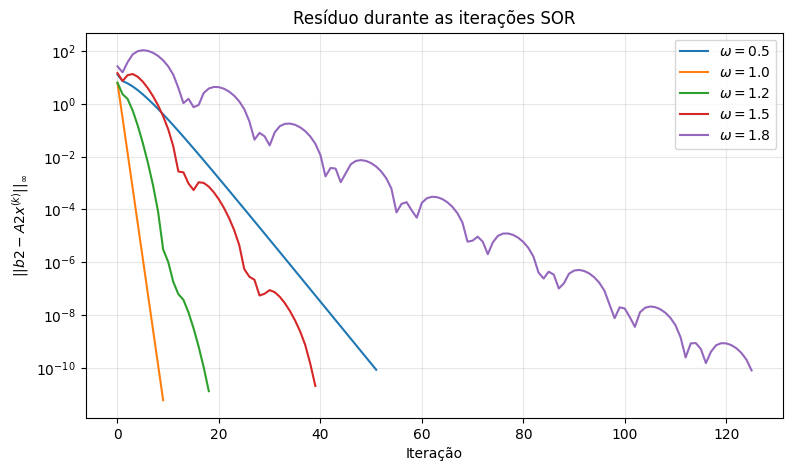

In [38]:
plt.figure(figsize=(9, 5))
for w in [0.5, 1.0, 1.2, 1.5, 1.8]:
    plt.semilogy(historicos[w]["residuo"], label=fr"$\omega={w}$")
plt.xlabel("Iteração")
plt.ylabel(r"$||b2-A2x^{(k)}||_\infty$")
plt.title("Resíduo durante as iterações SOR")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()
